In [1]:
import math
import random
import json
from plotly.offline import plot, iplot, init_notebook_mode
init_notebook_mode(connected=True)
from datetime import timedelta
from urllib.request import urlopen
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objs as go
import plotly.figure_factory as ff
from plotly.subplots import make_subplots
from pandas.plotting import register_matplotlib_converters
import warnings
warnings.filterwarnings('ignore')
import us
cnf, dth, rec, act = '#393e46', '#ff2e63', '#21bf73', '#fe9801' 
sns.set_style('darkgrid')

# Covid-19 Data for all countries

In [2]:
data = pd.read_csv("covid19data.csv")

# Covid-19 data for South Africa

In [3]:
data["date"] = pd.to_datetime(data["date"])
covid_data = data[(data["date"] >= "2020-01-01") & (data["date"] <= "2022-12-31")]

In [4]:
SA_covid_data = covid_data[data["country"] == "South Africa"]
SA_covid_data

,country,date,total_cases,new_cases,new_cases_smoothed,total_cases_per_million,new_cases_per_million,new_cases_smoothed_per_million,total_deaths,new_deaths,...,population,population_density,median_age,life_expectancy,gdp_per_capita,extreme_poverty,diabetes_prevalence,handwashing_facilities,hospital_beds_per_thousand,human_development_index
507105,South Africa,2020-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,62378417.0,51.421097,27.919001,65.453598,13592.048828,17.43592,7.2,44.369694,NaN,NaN
507106,South Africa,2020-01-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,62378417.0,51.421097,27.919001,65.453598,13592.048828,17.43592,7.2,44.369694,NaN,NaN
507107,South Africa,2020-01-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,62378417.0,51.421097,27.919001,65.453598,13592.048828,17.43592,7.2,44.369694,NaN,NaN
507108,South Africa,2020-01-04,0.0,0.0,NaN,0.000,0.000000,NaN,0.0,0.0,...,62378417.0,51.421097,27.919001,65.453598,13592.048828,17.43592,7.2,44.369694,NaN,NaN
507109,South Africa,2020-01-05,0.0,0.0,NaN,0.000,0.000000,NaN,0.0,0.0,...,62378417.0,51.421097,27.919001,65.453598,13592.048828,17.43592,7.2,44.369694,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
508196,South Africa,2022-12-27,4048281.0,49.0,239.71428,64898.746,0.785528,3.842904,102568.0,0.0,...,62378417.0,51.421097,27.919001,65.453598,13592.048828,17.43592,7.2,44.369694,NaN,NaN
508197,South Africa,2022-12-28,4048281.0,0.0,239.71428,64898.746,0.000000,3.842904,102568.0,0.0,...,62378417.0,51.421097,27.919001,65.453598,13592.048828,17.43592,7.2,44.369694,NaN,NaN
508198,South Africa,2022-12-29,4048580.0,299.0,282.42856,64903.540,4.793324,4.527665,102568.0,0.0,...,62378417.0,51.421097,27.919001,65.453598,13592.048828,17.43592,7.2,44.369694,NaN,NaN
508199,South Africa,2022-12-30,4048580.0,0.0,282.42856,64903.540,0.000000,4.527665,102568.0,0.0,...,62378417.0,51.421097,27.919001,65.453598,13592.048828,17.43592,7.2,44.369694,NaN,NaN


#### Covid-19 tests

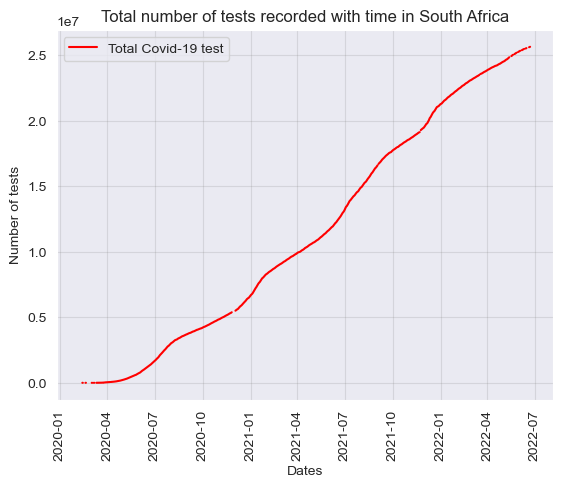

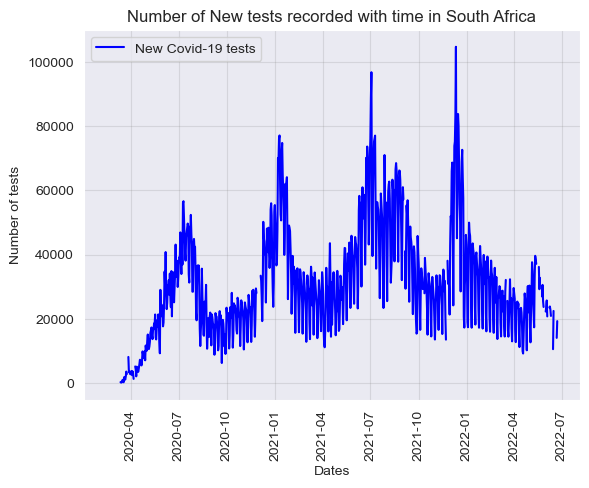

In [5]:
plt.plot(SA_covid_data["date"], SA_covid_data["total_tests"], color = "red", label = "Total Covid-19 test")
plt.title("Total number of tests recorded with time in South Africa")
plt.xlabel("Dates")
plt.ylabel("Number of tests")
plt.xticks(rotation = 90)
plt.grid(True, color = "grey", alpha = 0.2)
plt.legend()
plt.show()

plt.plot(SA_covid_data["date"], SA_covid_data["new_tests"], color = "blue", label = "New Covid-19 tests")
plt.title("Number of New tests recorded with time in South Africa")
plt.xlabel("Dates")
plt.ylabel("Number of tests")
plt.xticks(rotation = 90)
plt.grid(True, color = "grey", alpha = 0.2)
plt.legend()
plt.show()

#### Covid-19 cases

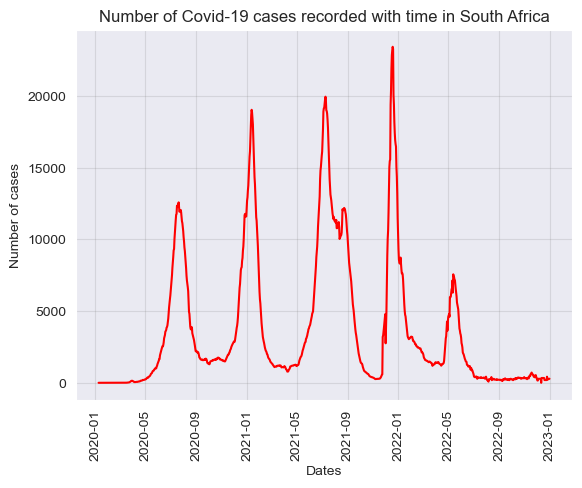

In [6]:
plt.plot(SA_covid_data["date"], SA_covid_data["new_cases_smoothed"], color = "red")
plt.title("Number of Covid-19 cases recorded with time in South Africa")
plt.xlabel("Dates")
plt.ylabel("Number of cases")
plt.xticks(rotation = 90)
plt.grid(True, color = "grey", alpha = 0.2)
plt.show()

#### Covid-19 hospitalized patients

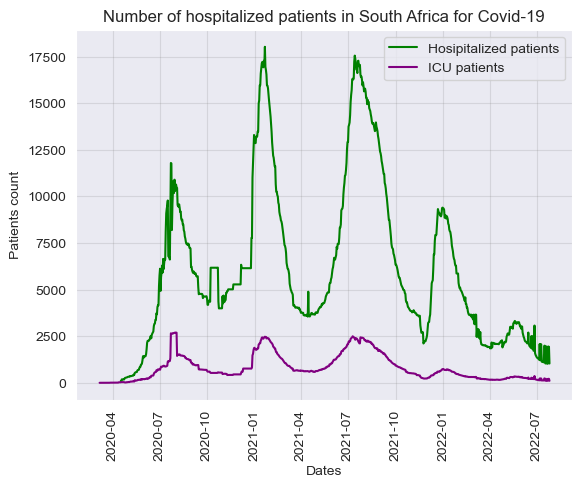

In [7]:
plt.plot(SA_covid_data["date"], SA_covid_data["hosp_patients"], color = "green", label = "Hosipitalized patients")
plt.plot(SA_covid_data["date"], SA_covid_data["icu_patients"], color = "purple", label = "ICU patients")
plt.title("Number of hospitalized patients in South Africa for Covid-19")
plt.ylabel("Patients count")
plt.xlabel("Dates")
plt.xticks(rotation = 90)
plt.grid(True, color = "grey", alpha = 0.2)
plt.legend()
plt.show()

#### Covid-19 deaths

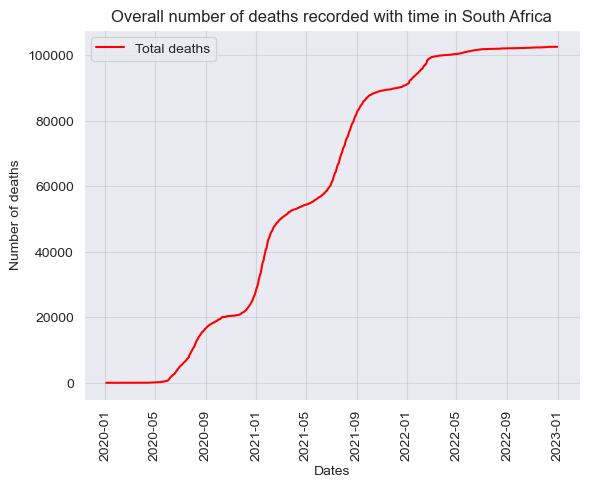

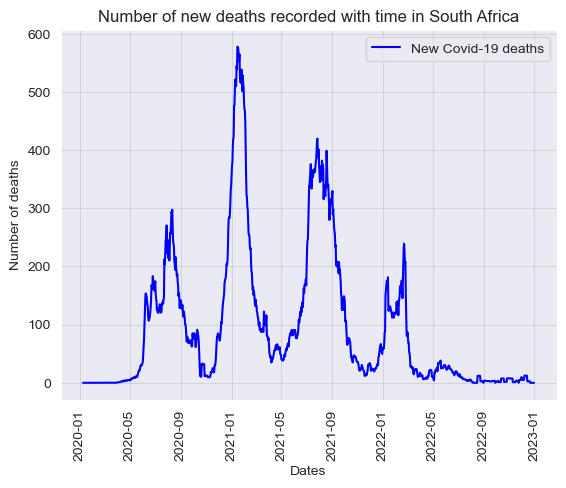

In [8]:
plt.plot(SA_covid_data["date"], SA_covid_data["total_deaths"], color = "red", label = "Total deaths")
plt.title("Overall number of deaths recorded with time in South Africa")
plt.xlabel("Dates")
plt.ylabel("Number of deaths")
plt.xticks(rotation = 90)
plt.grid(True, color = "grey", alpha = 0.2)
plt.legend()
plt.show()

plt.plot(SA_covid_data["date"], SA_covid_data["new_deaths_smoothed"], color = "blue", label = "New Covid-19 deaths")
plt.title("Number of new deaths recorded with time in South Africa")
plt.xlabel("Dates")
plt.ylabel("Number of deaths")
plt.xticks(rotation = 90)
plt.grid(True, color = "grey", alpha = 0.2)
plt.legend()
plt.show()

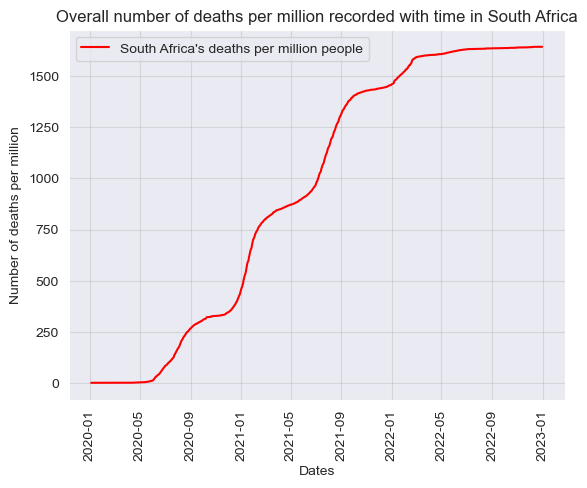

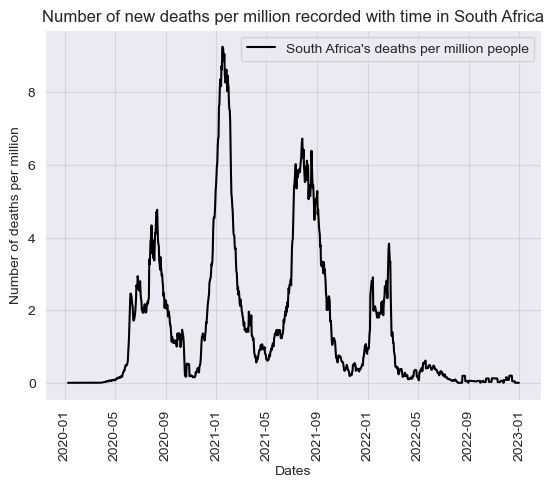

In [9]:
plt.plot(SA_covid_data["date"], SA_covid_data["total_deaths_per_million"], color = "red", label = "South Africa's deaths per million people")
plt.title("Overall number of deaths per million recorded with time in South Africa")
plt.xlabel("Dates")
plt.ylabel("Number of deaths per million")
plt.xticks(rotation = 90)
plt.grid(True, color = "grey", alpha = 0.2)
plt.legend()
plt.show()


plt.plot(SA_covid_data["date"], SA_covid_data["new_deaths_smoothed_per_million"], color = "black", label = "South Africa's deaths per million people")
plt.title("Number of new deaths per million recorded with time in South Africa")
plt.xlabel("Dates")
plt.ylabel("Number of deaths per million")
plt.xticks(rotation = 90)
plt.grid(True, color = "grey", alpha = 0.2)
plt.legend()
plt.show()

#### Covid-19 vaccinations

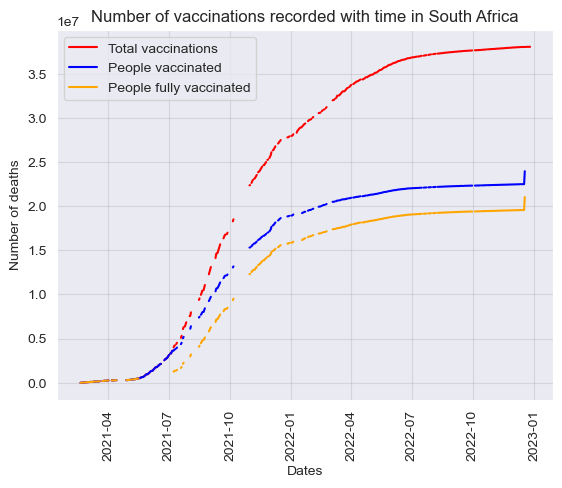

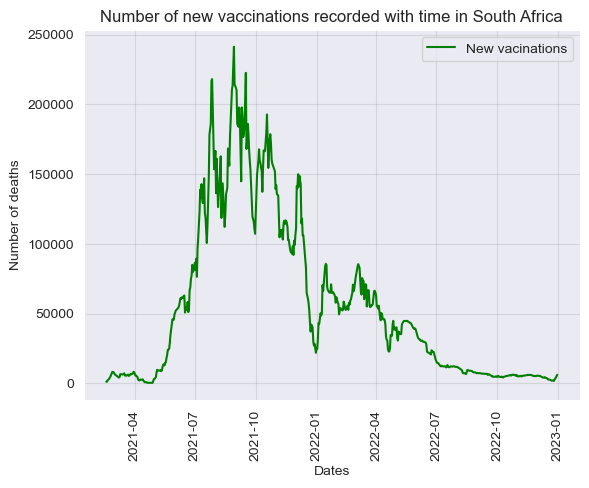

In [10]:
plt.plot(SA_covid_data["date"], SA_covid_data["total_vaccinations"], color = "red", label = "Total vaccinations")
plt.plot(SA_covid_data["date"], SA_covid_data["people_vaccinated"], color = "blue", label = "People vaccinated")
plt.plot(SA_covid_data["date"], SA_covid_data["people_fully_vaccinated"], color = "orange", label = "People fully vaccinated")
plt.title("Number of vaccinations recorded with time in South Africa")
plt.xlabel("Dates")
plt.ylabel("Number of deaths")
plt.xticks(rotation = 90)
plt.grid(True, color = "grey", alpha = 0.2)
plt.legend()
plt.show()

plt.plot(SA_covid_data["date"], SA_covid_data["new_vaccinations_smoothed"], color = "green", label = "New vacinations")
plt.title("Number of new vaccinations recorded with time in South Africa")
plt.xlabel("Dates")
plt.ylabel("Number of deaths")
plt.xticks(rotation = 90)
plt.grid(True, color = "grey", alpha = 0.2)
plt.legend()
plt.show()

# Comparing Covid-19 data of countries in Southern Africa

In [11]:
Nam_covid_data = covid_data[data["country"] == "Namibia"]
Bots_covid_data = covid_data[data["country"] == "Botswana"]
Zim_covid_data = covid_data[data["country"] == "Zimbabwe"]
Moz_covid_data = covid_data[data["country"] == "Mozambique"]
Swa_covid_data = covid_data[data["country"] == "Eswatini"]
Leso_covid_data = covid_data[data["country"] == "Lesotho"]

#### Covid-19 test

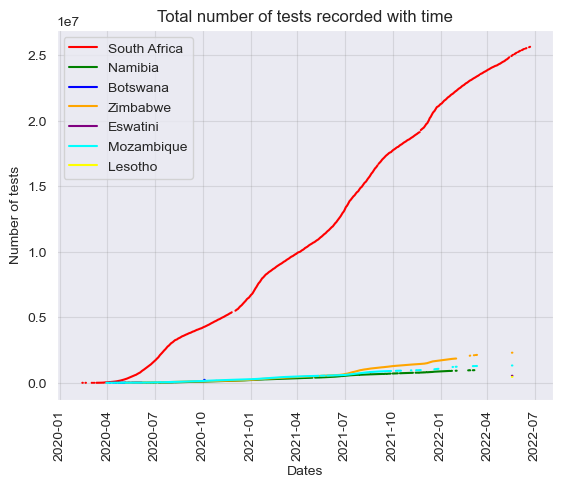

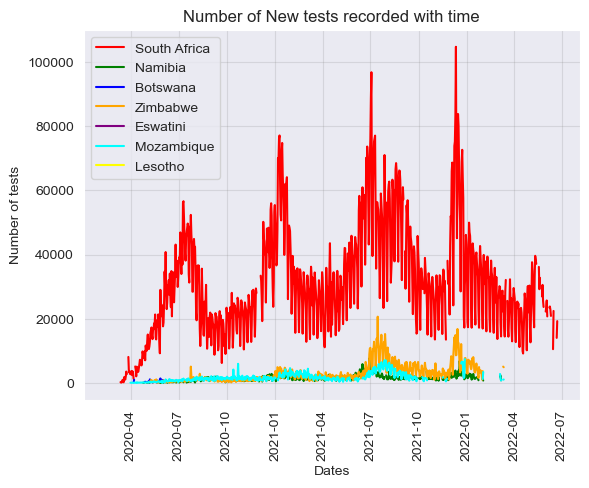

In [12]:
plt.plot(SA_covid_data["date"], SA_covid_data["total_tests"], color = "red", label = "South Africa")
plt.plot(SA_covid_data["date"], Nam_covid_data["total_tests"], color = "green", label = "Namibia")
plt.plot(SA_covid_data["date"], Bots_covid_data["total_tests"], color = "blue", label = "Botswana")
plt.plot(SA_covid_data["date"], Zim_covid_data["total_tests"], color = "orange", label = "Zimbabwe")
plt.plot(SA_covid_data["date"], Swa_covid_data["total_tests"], color = "purple", label = "Eswatini")
plt.plot(SA_covid_data["date"], Moz_covid_data["total_tests"], color = "cyan", label = "Mozambique")
plt.plot(SA_covid_data["date"], Leso_covid_data["total_tests"], color = "yellow", label = "Lesotho")
plt.title("Total number of tests recorded with time")
plt.xlabel("Dates")
plt.ylabel("Number of tests")
plt.xticks(rotation = 90)
plt.grid(True, color = "grey", alpha = 0.2)
plt.legend()
plt.show()

plt.plot(SA_covid_data["date"], SA_covid_data["new_tests"], color = "red", label = "South Africa")
plt.plot(SA_covid_data["date"], Nam_covid_data["new_tests"], color = "green", label = "Namibia")
plt.plot(SA_covid_data["date"], Bots_covid_data["new_tests"], color = "blue", label = "Botswana")
plt.plot(SA_covid_data["date"], Zim_covid_data["new_tests"], color = "orange", label = "Zimbabwe")
plt.plot(SA_covid_data["date"], Swa_covid_data["new_tests"], color = "purple", label = "Eswatini")
plt.plot(SA_covid_data["date"], Moz_covid_data["new_tests"], color = "cyan", label = "Mozambique")
plt.plot(SA_covid_data["date"], Leso_covid_data["new_tests"], color = "yellow", label = "Lesotho")
plt.title("Number of New tests recorded with time")
plt.xlabel("Dates")
plt.ylabel("Number of tests")
plt.xticks(rotation = 90)
plt.grid(True, color = "grey", alpha = 0.2)
plt.legend()
plt.show()

#### Covid-19 cases

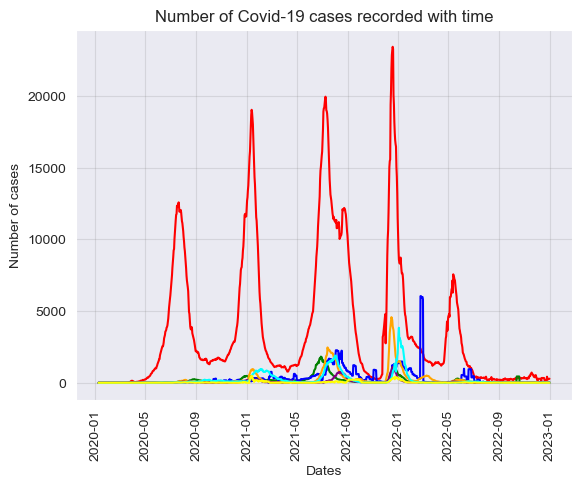

In [13]:
plt.plot(SA_covid_data["date"], SA_covid_data["new_cases_smoothed"], color = "red", label = "South Africa")
plt.plot(SA_covid_data["date"], Nam_covid_data["new_cases_smoothed"], color = "green", label = "Namibia")
plt.plot(SA_covid_data["date"], Bots_covid_data["new_cases_smoothed"], color = "blue", label = "Botswana")
plt.plot(SA_covid_data["date"], Zim_covid_data["new_cases_smoothed"], color = "orange", label = "Zimbabwe")
plt.plot(SA_covid_data["date"], Swa_covid_data["new_cases_smoothed"], color = "purple", label = "Eswatini")
plt.plot(SA_covid_data["date"], Moz_covid_data["new_cases_smoothed"], color = "cyan", label = "Mozambique")
plt.plot(SA_covid_data["date"], Leso_covid_data["new_cases_smoothed"], color = "yellow", label = "Lesotho")
plt.title("Number of Covid-19 cases recorded with time")
plt.xlabel("Dates")
plt.ylabel("Number of cases")
plt.xticks(rotation = 90)
plt.grid(True, color = "grey", alpha = 0.2)
plt.show()

#### Covid-19 deaths

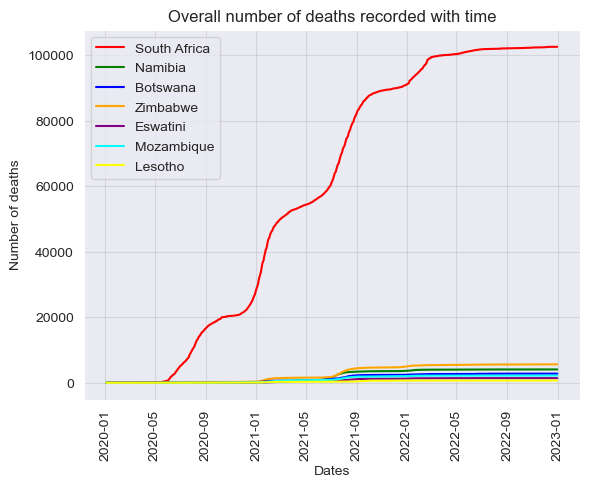

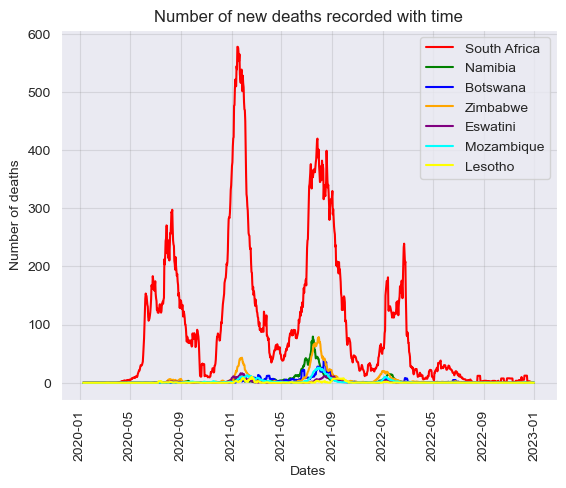

In [14]:
plt.plot(SA_covid_data["date"], SA_covid_data["total_deaths"], color = "red", label = "South Africa")
plt.plot(SA_covid_data["date"], Nam_covid_data["total_deaths"], color = "green", label = "Namibia")
plt.plot(SA_covid_data["date"], Bots_covid_data["total_deaths"], color = "blue", label = "Botswana")
plt.plot(SA_covid_data["date"], Zim_covid_data["total_deaths"], color = "orange", label = "Zimbabwe")
plt.plot(SA_covid_data["date"], Swa_covid_data["total_deaths"], color = "purple", label = "Eswatini")
plt.plot(SA_covid_data["date"], Moz_covid_data["total_deaths"], color = "cyan", label = "Mozambique")
plt.plot(SA_covid_data["date"], Leso_covid_data["total_deaths"], color = "yellow", label = "Lesotho")
plt.title("Overall number of deaths recorded with time")
plt.xlabel("Dates")
plt.ylabel("Number of deaths")
plt.xticks(rotation = 90)
plt.grid(True, color = "grey", alpha = 0.2)
plt.legend()
plt.show()

plt.plot(SA_covid_data["date"], SA_covid_data["new_deaths_smoothed"], color = "red", label = "South Africa")
plt.plot(SA_covid_data["date"], Nam_covid_data["new_deaths_smoothed"], color = "green", label = "Namibia")
plt.plot(SA_covid_data["date"], Bots_covid_data["new_deaths_smoothed"], color = "blue", label = "Botswana")
plt.plot(SA_covid_data["date"], Zim_covid_data["new_deaths_smoothed"], color = "orange", label = "Zimbabwe")
plt.plot(SA_covid_data["date"], Swa_covid_data["new_deaths_smoothed"], color = "purple", label = "Eswatini")
plt.plot(SA_covid_data["date"], Moz_covid_data["new_deaths_smoothed"], color = "cyan", label = "Mozambique")
plt.plot(SA_covid_data["date"], Leso_covid_data["new_deaths_smoothed"], color = "yellow", label = "Lesotho")
plt.title("Number of new deaths recorded with time")
plt.xlabel("Dates")
plt.ylabel("Number of deaths")
plt.xticks(rotation = 90)
plt.grid(True, color = "grey", alpha = 0.2)
plt.legend()
plt.show()

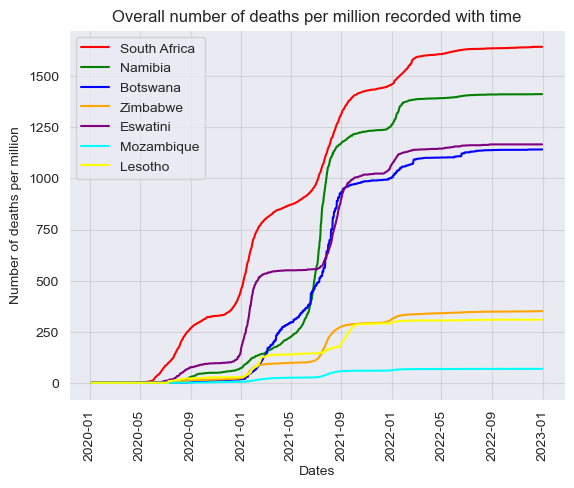

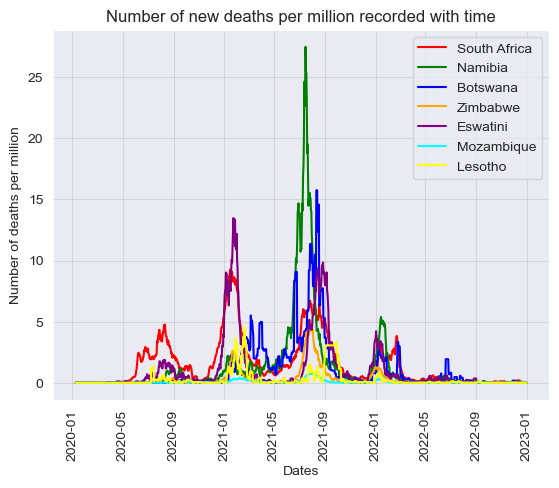

In [15]:
plt.plot(SA_covid_data["date"], SA_covid_data["total_deaths_per_million"], color = "red", label = "South Africa")
plt.plot(SA_covid_data["date"], Nam_covid_data["total_deaths_per_million"], color = "green", label = "Namibia")
plt.plot(SA_covid_data["date"], Bots_covid_data["total_deaths_per_million"], color = "blue", label = "Botswana")
plt.plot(SA_covid_data["date"], Zim_covid_data["total_deaths_per_million"], color = "orange", label = "Zimbabwe")
plt.plot(SA_covid_data["date"], Swa_covid_data["total_deaths_per_million"], color = "purple", label = "Eswatini")
plt.plot(SA_covid_data["date"], Moz_covid_data["total_deaths_per_million"], color = "cyan", label = "Mozambique")
plt.plot(SA_covid_data["date"], Leso_covid_data["total_deaths_per_million"], color = "yellow", label = "Lesotho")
plt.title("Overall number of deaths per million recorded with time")
plt.xlabel("Dates")
plt.ylabel("Number of deaths per million")
plt.xticks(rotation = 90)
plt.grid(True, color = "grey", alpha = 0.2)
plt.legend()
plt.show()


plt.plot(SA_covid_data["date"], SA_covid_data["new_deaths_smoothed_per_million"], color = "red", label = "South Africa")
plt.plot(SA_covid_data["date"], Nam_covid_data["new_deaths_smoothed_per_million"], color = "green", label = "Namibia")
plt.plot(SA_covid_data["date"], Bots_covid_data["new_deaths_smoothed_per_million"], color = "blue", label = "Botswana")
plt.plot(SA_covid_data["date"], Zim_covid_data["new_deaths_smoothed_per_million"], color = "orange", label = "Zimbabwe")
plt.plot(SA_covid_data["date"], Swa_covid_data["new_deaths_smoothed_per_million"], color = "purple", label = "Eswatini")
plt.plot(SA_covid_data["date"], Moz_covid_data["new_deaths_smoothed_per_million"], color = "cyan", label = "Mozambique")
plt.plot(SA_covid_data["date"], Leso_covid_data["new_deaths_smoothed_per_million"], color = "yellow", label = "Lesotho")
plt.title("Number of new deaths per million recorded with time")
plt.xlabel("Dates")
plt.ylabel("Number of deaths per million")
plt.xticks(rotation = 90)
plt.grid(True, color = "grey", alpha = 0.2)
plt.legend()
plt.show()

# Conclusion


#### Anlysis of COVID-19 data from Southern African countries like South Africa, Namibia, Botswana, Zimbabe, Eswatini, Mozambique and Lesotho shows the difference in the recorded values to the number of test, cases and deaths that were recorded. South Africa recorded the highest cumulative figures among these countries while the other countries have relatively lower values. The graphs plotted show te changes in the numbers of the pandamic with time, showing periods of increase and decrease in the numbers. 

#### The data however should be interpreted with care since these countries differ in terms of population size, testing capacities, healthcare systems and resources, and reporting practices, which influence the data that was collected. Lower numbers do not always reflect that a country experienced a small impact. A good comparison of the impact is seen through the deaths per million people graphs. 

#### This analysis shows how Python and data visialisation is used to understand the impact Covid-19 had on Southern African countries through the trends from the numbers collected. 